# 04 · Main sweep: H2 (IID) and H3 (non-IID)

- **H2:** IID clients → global sharpness ≈ 2/η for every K.
- **H3:** non-IID → global sharpness settles below 2/η (more with heterogeneity), the sharpest client sits at its own edge, and the K effect is gradual.

**Setup.** 10 clients, Dirichlet α ∈ {∞, 1, 0.1}, K ∈ {1, 2, 5, 10, 20}, η ∈ {0.02, 0.04}, seeds {0, 1}, 10k local steps each (60 runs). Equilibrium = median over the last 30% of measurements. Values are `·η/2`, so 1 = edge.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # repo root when run from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from eosfl import obs
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def edge_line(ax, y=1.0):
    ax.axhline(y, color="k", lw=0.8)

In [2]:
runs = obs.load_runs("fedavg_main"); traj = obs.load_traj("fedavg_main")
print(len(runs), "runs | statuses:", runs.status.value_counts().to_dict() if "status" in runs else "n/a")
AL = {np.inf: "α=∞ (IID)", 1.0: "α=1", 0.1: "α=0.1"}

60 runs | statuses: {'budget': 60}


## 1. How heterogeneous are the clients?

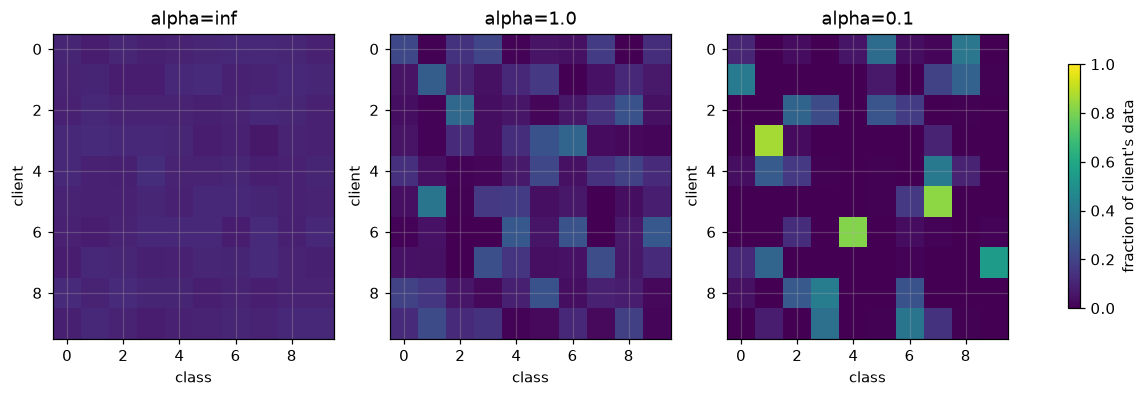

,split,min size,max size,mean classes ≥5%,mean label entropy (1 = uniform)
0,alpha=inf,500,500,10.0,1.00
1,alpha=1.0,304,896,5.7,0.83
2,alpha=0.1,132,893,3.2,0.47


In [3]:
splits = obs.load_splits("fedavg_main")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
rows = []
for ax, (key, sp) in zip(axes, sorted(splits.items(), key=lambda kv: -float(kv[0].split()[0].split("=")[1]))):
    L = np.array(sp["label_counts"], float); frac = L / L.sum(1, keepdims=True)
    im = ax.imshow(frac, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_title(key.split()[0]); ax.set_xlabel("class"); ax.set_ylabel("client")
    ent = -(frac * np.log(np.where(frac > 0, frac, 1))).sum(1) / np.log(10)
    rows.append({"split": key.split()[0], "min size": min(sp["sizes"]), "max size": max(sp["sizes"]),
                 "mean classes ≥5%": (frac >= 0.05).sum(1).mean(), "mean label entropy (1 = uniform)": ent.mean()})
fig.colorbar(im, ax=axes, shrink=0.8, label="fraction of client's data"); plt.show()
pd.DataFrame(rows).round(2)

## 2. Equilibrium tables (mean ± std over η and seed)

In [4]:
def table(col):
    g = runs.groupby(["alpha", "local_steps"])[col]
    m, s = g.mean().unstack(), g.std().unstack()
    out = m.round(3).astype(str) + " ± " + s.round(3).astype(str)
    out.index = [AL[a] for a in out.index]; return out.loc[[AL[a] for a in [np.inf, 1.0, 0.1]]]
print("global sharpness · η/2"); display(table("eq_sharp_norm"))
print("max client sharpness · η/2"); display(table("eq_client_norm"))

global sharpness · η/2


local_steps,1,2,5,10,20
α=∞ (IID),1.079 ± 0.009,1.063 ± 0.007,1.062 ± 0.006,1.061 ± 0.007,1.062 ± 0.005
α=1,1.077 ± 0.008,1.051 ± 0.003,1.053 ± 0.004,1.049 ± 0.004,1.047 ± 0.004
α=0.1,1.077 ± 0.008,1.006 ± 0.001,0.993 ± 0.002,0.978 ± 0.001,0.978 ± 0.004


max client sharpness · η/2


local_steps,1,2,5,10,20
α=∞ (IID),1.15 ± 0.014,1.129 ± 0.011,1.12 ± 0.01,1.112 ± 0.015,1.11 ± 0.008
α=1,1.238 ± 0.041,1.188 ± 0.022,1.166 ± 0.012,1.151 ± 0.015,1.15 ± 0.016
α=0.1,1.459 ± 0.133,1.235 ± 0.054,1.183 ± 0.02,1.148 ± 0.017,1.144 ± 0.021


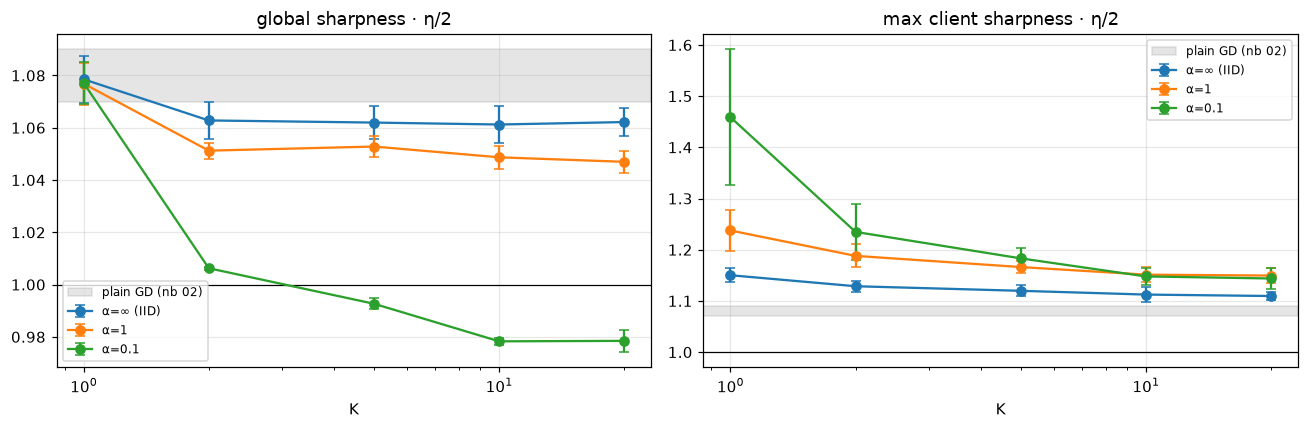

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], "eq_sharp_norm", "global sharpness · η/2"), (axes[1], "eq_client_norm", "max client sharpness · η/2")]:
    for a in [np.inf, 1.0, 0.1]:
        g = runs[runs.alpha == a].groupby("local_steps")[col].agg(["mean", "std"])
        ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3, label=AL[a])
    edge_line(ax); ax.axhspan(1.07, 1.09, color="grey", alpha=0.2, label="plain GD (nb 02)")
    ax.set_xscale("log"); ax.set_xlabel("K"); ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. H2 check (IID)

In [6]:
iid = runs[runs.alpha == np.inf]
k1 = iid[iid.local_steps == 1].eq_sharp_norm; kk = iid[iid.local_steps > 1]
print(f"K=1 global: {k1.mean():.3f} ± {k1.std():.3f}")
print(f"K≥2 global: {kk.eq_sharp_norm.mean():.3f} ± {kk.eq_sharp_norm.std():.3f}  "
      f"(range of K-means: {kk.groupby('local_steps').eq_sharp_norm.mean().agg(['min','max']).round(3).tolist()})")
print("by η:"); display(iid.groupby(["lr", "local_steps"]).eq_sharp_norm.mean().unstack().round(3))

K=1 global: 1.079 ± 0.009
K≥2 global: 1.062 ± 0.006  (range of K-means: [1.061, 1.063])
by η:


local_steps,1,2,5,10,20
lr,,,,,
0.02,1.071,1.057,1.057,1.055,1.058
0.04,1.086,1.069,1.067,1.067,1.066


## 4. H3 checks (non-IID)

In [7]:
m = runs.groupby(["alpha", "local_steps"]).eq_sharp_norm.mean().unstack()
c = runs.groupby(["alpha", "local_steps"]).eq_client_norm.mean().unstack()
print("ordering at each K (global, should be ∞ > 1 > 0.1):")
display((m.loc[np.inf] > m.loc[1.0]) & (m.loc[1.0] > m.loc[0.1]))
print("gap IID − α=0.1, global:"); display((m.loc[np.inf] - m.loc[0.1]).round(3))
print("K effect at α=0.1 (global): K1→K2 =", round(m.loc[0.1, 2] - m.loc[0.1, 1], 3),
      "| K2→K20 =", round(m.loc[0.1, 20] - m.loc[0.1, 2], 3))
print("max client at large K, by α:"); display(c[[10, 20]].round(3))

ordering at each K (global, should be ∞ > 1 > 0.1):


local_steps
1     False
2      True
5      True
10     True
20     True
dtype: bool

gap IID − α=0.1, global:


local_steps
1     0.001
2     0.057
5     0.069
10    0.083
20    0.084
dtype: float64

K effect at α=0.1 (global): K1→K2 = -0.071 | K2→K20 = -0.028
max client at large K, by α:


local_steps,10,20
alpha,,
0.1,1.148,1.144
1.0,1.151,1.150
inf,1.112,1.110


## 5. All clients at equilibrium: K = 1 vs K = 20

Each dot is one client's median sharpness·η/2 over the last 30% of a run (η = 0.02, both seeds).

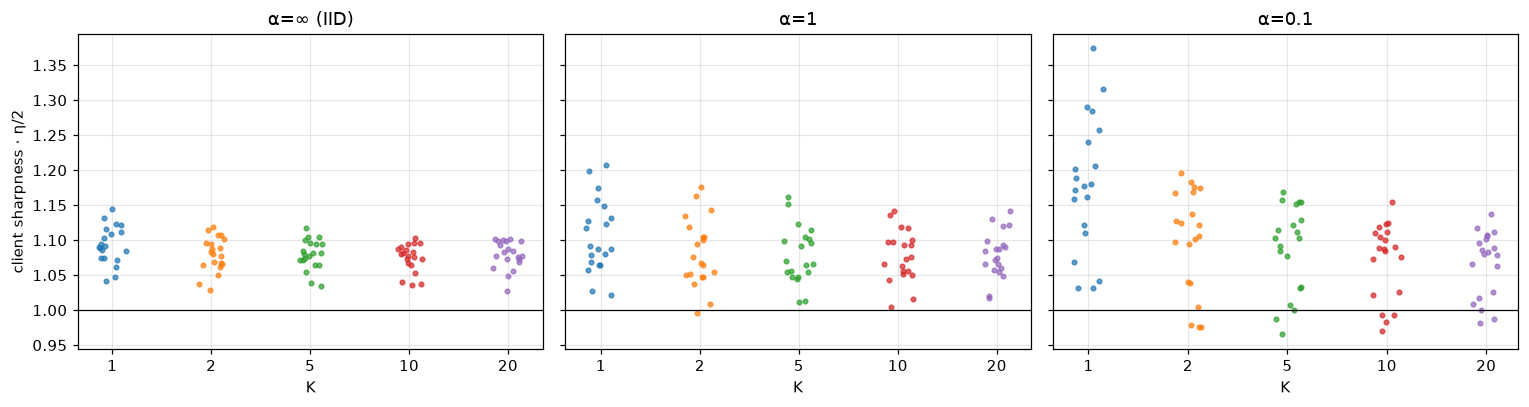

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, a in zip(axes, [np.inf, 1.0, 0.1]):
    for j, K in enumerate([1, 2, 5, 10, 20]):
        vals = []
        for run, g in traj[(traj.alpha == a) & (traj.local_steps == K) & np.isclose(traj.lr, 0.02)].groupby("run"):
            cc = g.dropna(subset=["client_sharp"]); cc = cc[cc.steps >= cc.steps.max() * 0.7]
            vals += list(np.median(np.vstack(cc.client_sharp.values), 0) * 0.02 / 2)
        ax.plot(np.full(len(vals), j) + np.random.uniform(-0.15, 0.15, len(vals)), vals, "o", ms=3, alpha=0.7)
    edge_line(ax); ax.set_xticks(range(5)); ax.set_xticklabels([1, 2, 5, 10, 20]); ax.set_xlabel("K"); ax.set_title(AL[a])
axes[0].set_ylabel("client sharpness · η/2"); plt.tight_layout(); plt.show()

## 6. Trajectories (η = 0.02, seed 0)

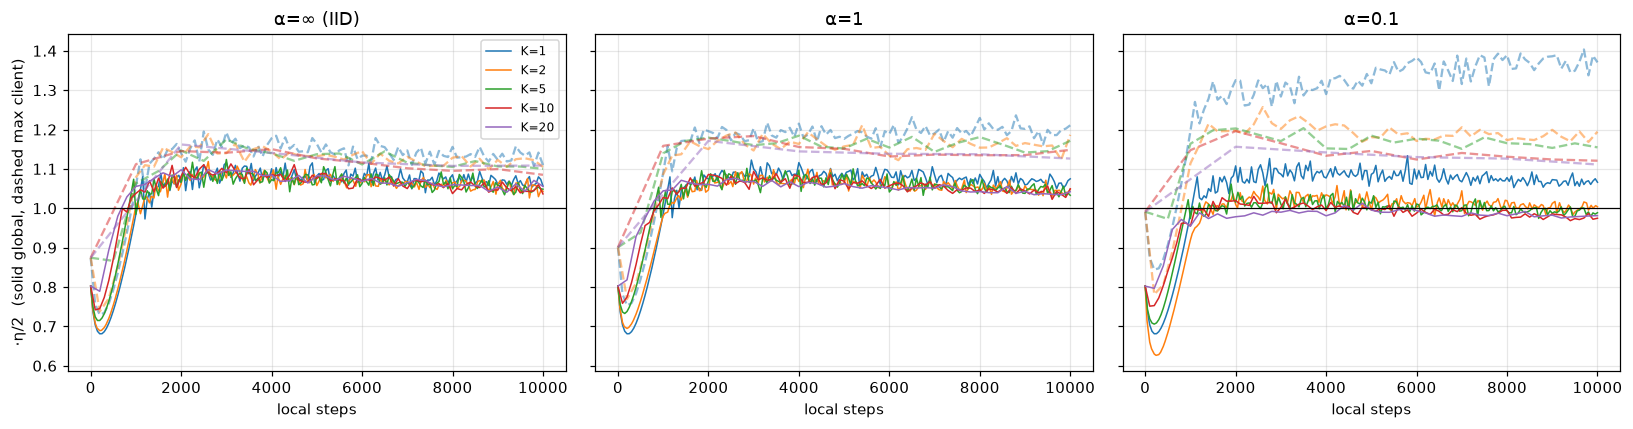

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, a in zip(axes, [np.inf, 1.0, 0.1]):
    for K, g in traj[(traj.alpha == a) & np.isclose(traj.lr, 0.02) & (traj.seed == 0)].groupby("local_steps"):
        s = g.dropna(subset=["sharpness"]); line, = ax.plot(s.steps, s.sharpness * 0.01, lw=1, label=f"K={K}")
        cc = g.dropna(subset=["client_sharp_max"]); ax.plot(cc.steps, cc.client_sharp_max * 0.01, "--", color=line.get_color(), alpha=0.5)
    edge_line(ax); ax.set_title(AL[a]); ax.set_xlabel("local steps")
axes[0].set_ylabel("·η/2  (solid global, dashed max client)"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. Comparison with the SOTA paper and side metrics

In [10]:
runs["eq_x_lr"] = runs.eq_sharpness * runs.lr
print("1/η scaling: equilibrium sharpness × η (should not depend on η)")
display(runs.groupby(["lr"]).eq_x_lr.agg(["mean", "std"]).round(4))
print("final train loss / test accuracy (mean over η, seed)")
display(runs.groupby(["alpha", "local_steps"])[["final_train_loss", "final_test_acc"]].mean().unstack(0).round(3))

1/η scaling: equilibrium sharpness × η (should not depend on η)


,mean,std
lr,,
0.02,2.078,0.063
0.04,2.091,0.076


final train loss / test accuracy (mean over η, seed)


final_train_loss               final_test_acc              
alpha                    0.1    1.0    inf            0.1    1.0    inf
local_steps                                                            
1                      0.055  0.055  0.050          0.317  0.318  0.322
2                      0.056  0.051  0.050          0.311  0.317  0.314
5                      0.070  0.059  0.052          0.312  0.313  0.307
10                     0.087  0.058  0.054          0.296  0.313  0.318
20                     0.112  0.063  0.055          0.282  0.313  0.320

## Conclusions

1. **H2 holds.** IID: the equilibrium is flat in K for K ≥ 2 (≈1.06) and slightly higher at K = 1 (≈1.08), the same overshoot band as plain GD (sections 2, 3).
2. **H3 holds in direction.** Global sharpness falls with heterogeneity at every K ≥ 2 (ordering ∞ > 1 > 0.1). At α = 0.1 it goes below the edge (≈0.98): FedAvg trains stably while the global loss is not at EoS (section 4).
3. **The binding constraint moves to the sharpest client.** At K = 1 individual clients can be far past their edge (one local step only sees the average Hessian). As K grows they are pulled into a narrow band (section 5).
4. **H3 fails in size.** The toy predicted a global value of ≈0.6–0.75; the network gives ≈0.98. The sharpest client sits ≈11–15% above its own edge rather than at it, at a level nearly independent of α for large K.
5. **K matters only through heterogeneity.** IID and α = 1: almost no K effect after K = 2 (agrees with the SOTA paper). α = 0.1: K lowers the equilibrium by ≈10%, mostly between K = 1 and 2, saturating by K ≈ 10 (refines the SOTA claim).
6. **1/η scaling holds** (section 7). Heterogeneity slows training (higher final loss at α = 0.1); test accuracy is ≈30% everywhere, as expected for a 5k-sample MLP used to study stability.